# **Section 3**: Data Handling, Analysis, and Visualization

Candidates should be able to load, clean, and manipulate data using Python, analyze numerical and categorical values, and prepare simple feature sets for AI tasks. They should understand how to visualize data to reveal trends and evaluate quality, and explain how data issues impact AI model reliability.

## 3.1 – Handle and Process Data Using Python

Keywords: CSV, JSON, lists, dictionaries, data cleaning, missing values, type conversion, data structures, input/output

### A. Read and write data from common file formats (CSV, text, JSON)

For basic ML tasks without `pandas`, Python relies on the built-in `csv` and `json` modules. 
*   **Text files:** Handled using the built-in `open()` function.
*   **CSV files:** Handled using the `csv` module. `csv.DictReader` and `csv.DictWriter` are highly recommended as they map rows directly to dictionaries, linking perfectly with Objective B.
*   **JSON files:** Handled using the `json` module, which maps JSON objects to Python dictionaries and JSON arrays to Python lists.

In [1]:
import csv
import json
import os

# --- 1. TEXT FILES ---
text_file_path = "sample_data.txt"

# Writing to a text file
with open(text_file_path, 'w', encoding='utf-8') as file:
    file.write("Machine Learning is fascinating.\nData processing is crucial.\n")

# Reading from a text file
with open(text_file_path, 'r', encoding='utf-8') as file:
    lines = file.readlines()
    print("Text File Content:")
    print([line.strip() for line in lines]) # .strip() removes newline characters

# --- 2. CSV FILES ---
csv_file_path = "sample_dataset.csv"
csv_data = [
    {"id": 1, "name": "Alice", "score": "85.5", "status": "active"},
    {"id": 2, "name": "Bob", "score": "N/A", "status": "inactive"},
    {"id": 3, "name": "Charlie", "score": "92.0", "status": "active"}
]

# Writing CSV using DictWriter
with open(csv_file_path, 'w', newline='', encoding='utf-8') as file:
    fieldnames = ["id", "name", "score", "status"]
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(csv_data)

# Reading CSV using DictReader
print("\nCSV File Content:")
with open(csv_file_path, 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file)
    for row in reader:
        print(row) # Notice everything is read as a string

# --- 3. JSON FILES ---
json_file_path = "sample_config.json"
json_data = {"model": "RandomForest", "hyperparameters": {"estimators": 100, "max_depth": 5}}

# Writing JSON
with open(json_file_path, 'w', encoding='utf-8') as file:
    json.dump(json_data, file, indent=4)

# Reading JSON
print("\nJSON File Content:")
with open(json_file_path, 'r', encoding='utf-8') as file:
    loaded_json = json.load(file)
    print(loaded_json)

# Cleanup (optional, keeping directory clean)
os.remove(text_file_path)
os.remove(csv_file_path)
os.remove(json_file_path)

Text File Content:
['Machine Learning is fascinating.', 'Data processing is crucial.']

CSV File Content:
{'id': '1', 'name': 'Alice', 'score': '85.5', 'status': 'active'}
{'id': '2', 'name': 'Bob', 'score': 'N/A', 'status': 'inactive'}
{'id': '3', 'name': 'Charlie', 'score': '92.0', 'status': 'active'}

JSON File Content:
{'model': 'RandomForest', 'hyperparameters': {'estimators': 100, 'max_depth': 5}}


### B. Use Python data structures (lists, dictionaries, lists of dictionaries) to store and organize datasets
### C. Access, modify, and extract values from nested structures

In pure Python, a dataset is standardly represented as a **list of dictionaries**. Each dictionary represents a row (or observation), and keys represent column names (features).

JSON data from APIs often comes in heavily **nested structures** (dictionaries inside lists inside dictionaries). Navigating these requires precise key and index chaining, and safe extraction methods like `.get()` to avoid `KeyError`.

In [3]:
# A complex nested data structure (e.g., simulated API response)
api_response = {
    "metadata": {
        "status": "success",
        "timestamp": "2026-09-07T10:00:00Z",
        "total_results": 2
    },
    "data": [
        {
            "patient_id": "P001",
            "demographics": {"age": 45, "gender": "M"},
            "vitals": [{"type": "blood_pressure", "value": "120/80"}, {"type": "heart_rate", "value": 72}]
        },
        {
            "patient_id": "P002",
            "demographics": {"age": 30, "gender": "F"},
            "vitals": [{"type": "blood_pressure", "value": "110/70"}] # Missing heart rate
        }
    ]
}

# 1. Accessing values from nested structures
status = api_response["metadata"]["status"]
print(f"API Status: {status}")

# 2. Iterating through a list of dictionaries and extracting nested data
print("\nExtracting Patient Data:")
for patient in api_response["data"]:
    p_id = patient["patient_id"]
    age = patient["demographics"]["age"]
    
    # Using a list comprehension to filter a nested list of dicts
    bp_record = [v["value"] for v in patient["vitals"] if v["type"] == "blood_pressure"]
    bp_value = bp_record[0] if bp_record else "Unknown"
    
    print(f"Patient {p_id}: Age {age}, Blood Pressure: {bp_value}")

# 3. Safe extraction using .get() to prevent KeyError if a key doesn't exist
# E.g., getting a non-existent 'medical_history' key
history = api_response["data"][0].get("medical_history", "No history available")
print(f"\nMedical History check: {history}")

API Status: success

Extracting Patient Data:
Patient P001: Age 45, Blood Pressure: 120/80
Patient P002: Age 30, Blood Pressure: 110/70

Medical History check: No history available


### D. Identify and correct basic data inconsistencies (missing values, type mismatches, formatting errors)
### E. Convert between data types when preparing data (e.g., strings ↔ numbers)

When reading data from text or CSV files, **all data is initially parsed as strings**. You must explicitly convert (cast) them to integers or floats for machine learning calculations.

**Common inconsistencies:**
1.  **Missing values:** Represented as empty strings `""`, `"N/A"`, `"null"`, or actual `None` types.
2.  **Type mismatches:** Attempting to convert `"N/A"` to a float will raise a `ValueError`.
3.  **Formatting errors:** Whitespaces around strings (`"  active  "`), or incorrect delimiters.

To handle this, we use `try-except` blocks and conditional logic to clean the data during the ingestion phase.

In [4]:
# Raw dataset simulating data directly read from a CSV (all strings, contains inconsistencies)
raw_dataset = [
    {"id": "1", "name": " Alice ", "age": "25", "salary": "50000.50"},
    {"id": "2", "name": "Bob", "age": "N/A", "salary": "60000.00"},
    {"id": "3", "name": "Charlie", "age": "", "salary": "missing"},
    {"id": "4", "name": "David", "age": "30", "salary": " 75000 "}
]

def clean_record(row):
    """
    Takes a raw dictionary row and returns a cleaned, type-casted version.
    Fills missing or invalid numerical data with None.
    """
    cleaned_row = {}
    
    # 1. Clean formatting (strip whitespaces from strings)
    cleaned_row["id"] = int(row["id"]) # ID should always be an integer
    cleaned_row["name"] = row["name"].strip()
    
    # 2. Handle missing values and type conversion for Age
    age_str = row["age"].strip()
    if age_str in ("", "N/A", "missing", "null"):
        cleaned_row["age"] = None
    else:
        try:
            cleaned_row["age"] = int(age_str)
        except ValueError:
            cleaned_row["age"] = None
            
    # 3. Handle missing values and type conversion for Salary
    salary_str = row["salary"].strip()
    try:
        # Convert string to float
        cleaned_row["salary"] = float(salary_str)
    except ValueError:
        # Catch type mismatch (e.g., trying to float("missing"))
        cleaned_row["salary"] = None
        
    return cleaned_row

# Processing the entire dataset
cleaned_dataset = [clean_record(row) for row in raw_dataset]

print("Raw Dataset:")
for row in raw_dataset:
    print(row)

print("\nCleaned & Type-Casted Dataset:")
for row in cleaned_dataset:
    print(row)

# Notice how strings like "25" became int 25, and "missing" or "N/A" became None type.

Raw Dataset:
{'id': '1', 'name': ' Alice ', 'age': '25', 'salary': '50000.50'}
{'id': '2', 'name': 'Bob', 'age': 'N/A', 'salary': '60000.00'}
{'id': '3', 'name': 'Charlie', 'age': '', 'salary': 'missing'}
{'id': '4', 'name': 'David', 'age': '30', 'salary': ' 75000 '}

Cleaned & Type-Casted Dataset:
{'id': 1, 'name': 'Alice', 'age': 25, 'salary': 50000.5}
{'id': 2, 'name': 'Bob', 'age': None, 'salary': 60000.0}
{'id': 3, 'name': 'Charlie', 'age': None, 'salary': None}
{'id': 4, 'name': 'David', 'age': 30, 'salary': 75000.0}


## 3.2 - Analyze Numerical and Categorical Data in Python

Keywords: mean, median, min/max, frequency, grouping, summarizing, sorting, math module, numeric analysis, patterns

### A. Calculate basic statistical measures such as mean, median, minimum, maximum, and frequency counts

### E. Use the math module for simple numeric operations and formulas. 

*   **Mean:** The mathematical average. Can be calculated using standard `sum()` or `math.fsum()` for better float precision.
*   **Median:** The middle value of a sorted dataset. If the dataset has an even number of elements, it is the average of the two middle values.
*   **Min/Max:** Easily found using Python's built-in `min()` and `max()` functions.
*   **Frequency:** Counting occurrences of categorical or numerical values, typically using dictionaries.
*   **Math module:** Provides access to mathematical functions like `sqrt()`, `ceil()`, `floor()`, and constants like `pi`.

In [5]:
import math

# Sample numerical data
data = [12, 15, 22, 15, 30, 8, 12, 15, 40]

# 1. Min and Max (Built-in functions)
min_val = min(data)
max_val = max(data)

# 2. Mean (Using math.fsum for accurate floating-point summation)
mean_val = math.fsum(data) / len(data) if data else 0

# 3. Median (Requires sorting the data first)
sorted_data = sorted(data)
n = len(sorted_data)
mid = n // 2

if n % 2 == 0:
    # Even number of elements: average of the two middle elements
    median_val = (sorted_data[mid - 1] + sorted_data[mid]) / 2.0
else:
    # Odd number of elements: the exact middle element
    median_val = sorted_data[mid]

# 4. Frequency Counts (Categorical or Numerical)
frequency = {}
for item in data:
    frequency[item] = frequency.get(item, 0) + 1

# 5. Using math module for simple operations (e.g., standard deviation foundation)
# Calculating variance as an example of math operations
variance = sum(math.pow(x - mean_val, 2) for x in data) / len(data)
std_dev = math.sqrt(variance)

print(f"Data: {sorted_data}")
print(f"Min: {min_val}, Max: {max_val}")
print(f"Mean: {mean_val:.2f}, Median: {median_val}")
print(f"Frequencies: {frequency}")
print(f"Standard Deviation: {std_dev:.2f}")

Data: [8, 12, 12, 15, 15, 15, 22, 30, 40]
Min: 8, Max: 40
Mean: 18.78, Median: 15
Frequencies: {12: 2, 15: 3, 22: 1, 30: 1, 8: 1, 40: 1}
Standard Deviation: 9.65


### B. Group and summarize small datasets using Python loops and comprehensions
### C. Sort data by selected attributes (e.g., by score, by category)
### D. Identify patterns or trends in small datasets (e.g., most common category, highest/lowest values)

When dealing with structured data (list of dictionaries), you need to manipulate it to extract insights.

*   **Sorting:** Done via the `sorted()` function or list `.sort()` method, combined with a `lambda` function to specify which dictionary key to sort by.
*   **Grouping & Summarizing:** Without SQL's `GROUP BY`, you iterate through the dataset and use a dictionary where keys are the grouping categories and values are lists of items belonging to that category.
*   **Identifying Patterns:** Trends like "most common category" or "highest performer" are found by querying the summarized data or sorted lists.

In [6]:
# Dataset: List of dictionaries representing employees
dataset = [
    {"name": "Alice", "department": "HR", "score": 85},
    {"name": "Bob", "department": "IT", "score": 92},
    {"name": "Charlie", "department": "IT", "score": 78},
    {"name": "David", "department": "HR", "score": 90},
    {"name": "Eve", "department": "Sales", "score": 88},
    {"name": "Frank", "department": "IT", "score": 95}
]

# --- 1. SORTING DATA ---
# Sort by score in descending order (highest first)
sorted_by_score = sorted(dataset, key=lambda x: x['score'], reverse=True)

print("Top 2 Performers (Highest Values):")
for employee in sorted_by_score[:2]:
    print(f"- {employee['name']}: {employee['score']}")

# --- 2. GROUPING DATA ---
# Group scores by department
dept_scores = {}
for row in dataset:
    dept = row['department']
    score = row['score']
    
    if dept not in dept_scores:
        dept_scores[dept] = [] # Initialize empty list for new department
    dept_scores[dept].append(score)

# --- 3. SUMMARIZING DATA (Using comprehensions) ---
# Calculate average score per department
dept_averages = {
    dept: sum(scores) / len(scores) 
    for dept, scores in dept_scores.items()
}

print("\nAverage Score by Department:")
for dept, avg in dept_averages.items():
    print(f"- {dept}: {avg:.1f}")

# --- 4. IDENTIFYING PATTERNS ---
# Find the most common category (department with the most employees)
dept_counts = {dept: len(scores) for dept, scores in dept_scores.items()}

# max() with a key parameter allows us to find the dictionary key with the highest value
most_common_dept = max(dept_counts, key=dept_counts.get)

print(f"\nPattern Identified:")
print(f"- Most common department is '{most_common_dept}' with {dept_counts[most_common_dept]} employees.")

Top 2 Performers (Highest Values):
- Frank: 95
- Bob: 92

Average Score by Department:
- HR: 87.5
- IT: 88.3
- Sales: 88.0

Pattern Identified:
- Most common department is 'IT' with 3 employees.


## 3.3 - Work With Numerical Data and Distances for AI Tasks

Keywords: vector, Euclidean distance, Manhattan distance, similarity, normalization, scaling, features, numerical data, simple ML logic

### A. Interpret lists of numbers as vectors suitable for simple ML-style operations
### D. Prepare basic feature sets for simple AI experiments (e.g., using height/weight pairs or text frequency counts)

A **vector** in machine learning is simply an ordered list of numbers representing an object's characteristics (features). 
*   In pure Python, vectors are represented as `lists` or `tuples`.
*   **Feature sets** are collections of these vectors.
*   *Example 1:* A person can be represented by a numerical vector `[height, weight]`.
*   *Example 2:* A text document can be represented by a frequency count of specific words (Bag of Words).

In [7]:
# 1. Preparing basic feature sets (Point D)

# Example: Dataset of height (cm) and weight (kg) pairs
# Each tuple is a vector representing one individual
people_data = [
    (170, 65), # Person A
    (180, 80), # Person B
    (160, 55), # Person C
]

# Example: Text frequency counts (Bag of Words)
# Vocabulary: ["AI", "Python", "Data"]
# Vector represents how many times each word appeared in a text
text_vectors = [
    [2, 1, 0], # Text 1: "AI AI Python"
    [0, 3, 2], # Text 2: "Python Python Python Data Data"
]

print(f"Vector for Person B: {people_data[1]}")
print(f"Frequency vector for Text 2: {text_vectors[1]}")

Vector for Person B: (180, 80)
Frequency vector for Text 2: [0, 3, 2]


### B. Calculate Euclidean and Manhattan distance, and other simple similarity measures using Python

Distance metrics define how "similar" two vectors are. A smaller distance means higher similarity.

1.  **Euclidean Distance:** The shortest straight-line distance between two points.
    *   Formula: `sqrt((x1-y1)^2 + (x2-y2)^2 + ...)`
2.  **Manhattan Distance (City Block):** The distance between two points measured along axes at right angles.
    *   Formula: `|x1-y1| + |x2-y2| + ...`
3.  **Cosine Similarity:** Measures the angle between two vectors rather than their length. It is widely used for text data because it ignores document length and focuses on word orientation
    *   Formula: 

$$
S_C(A, B) = \cos(\theta) = \frac{A \cdot B}{\|A\|\,\|B\|}
= \frac{\sum_{i=1}^{n} A_i B_i}
{\sqrt{\sum_{i=1}^{n} A_i^2}\sqrt{\sum_{i=1}^{n} B_i^2}}
$$

In [17]:
import math

def euclidean_distance(v1, v2):
    """Calculates the straight-line distance between two vectors."""
    if len(v1) != len(v2):
        raise ValueError("Vectors must have the same length.")
    return math.sqrt(sum((a - b) ** 2 for a, b in zip(v1, v2)))

def manhattan_distance(v1, v2):
    """Calculates the sum of absolute differences across all dimensions."""
    if len(v1) != len(v2):
        raise ValueError("Vectors must have the same length.")
    return sum(abs(a - b) for a, b in zip(v1, v2))

def cosine_similarity(v1, v2):
    dot_product = sum(a * b for a, b in zip(v1, v2))
    
    norm_a = math.sqrt(sum(a ** 2 for a in v1))
    norm_b = math.sqrt(sum(b ** 2 for b in v2))
    
    return dot_product / (norm_a * norm_b)

# Testing distances on our people data
person_a = people_data[0] # (170, 65)
person_b = people_data[1] # (180, 80)

euclidean = euclidean_distance(person_a, person_b)
manhattan = manhattan_distance(person_a, person_b)
cosine = cosine_similarity(person_a, person_b)

print(f"Euclidean distance between A and B: {euclidean:.2f}")
print(f"Manhattan distance between A and B: {manhattan:.2f}")
print(f"Cosine similarity between A and B: {cosine:.5f}")

Euclidean distance between A and B: 18.03
Manhattan distance between A and B: 25.00
Cosine similarity between A and B: 0.99859


### C. Normalize numeric values within a range (e.g., 0–1) to make data comparable
### E. Recognize when normalization, scaling, or distance metrics are necessary in AI workflows

**Normalization (Min-Max Scaling)** transforms features to be on a similar scale, typically between 0 and 1. 

*   **Formula:** `x_normalized = (x - min) / (max - min)`

**When and why is this necessary? (Point E)**
*   Distance-based algorithms (like k-NN or clustering) are highly sensitive to the scale of the data. 
*   If Feature 1 ranges from 0-1000 (e.g., salary) and Feature 2 ranges from 0-1 (e.g., test score), Feature 1 will completely dominate the distance calculation.
*   Scaling ensures that all features contribute equally to the final AI decision.

In [18]:
def normalize_feature(column):
    """Applies Min-Max scaling to a single list of numbers (0 to 1 range)."""
    min_val = min(column)
    max_val = max(column)
    
    # Handle the edge case where all values in the column are the same
    if min_val == max_val:
        return [0.0 for _ in column]
        
    return [(x - min_val) / (max_val - min_val) for x in column]

# A dataset where features have vastly different scales
# [Age, Income]
raw_dataset = [
    [25, 50000],
    [45, 120000],
    [30, 60000],
    [50, 150000]
]

# To normalize, we need to extract columns first (transpose the list of lists)
ages = [row[0] for row in raw_dataset]
incomes = [row[1] for row in raw_dataset]

# Apply normalization
normalized_ages = normalize_feature(ages)
normalized_incomes = normalize_feature(incomes)

# Reconstruct the dataset
normalized_dataset = [
    [age, income] for age, income in zip(normalized_ages, normalized_incomes)
]

print("Raw Dataset (Age, Income):")
for row in raw_dataset:
    print(row)

print("\nNormalized Dataset (0-1 scale):")
for row in normalized_dataset:
    # Formatting to 3 decimal places for readability
    print(f"[{row[0]:.3f}, {row[1]:.3f}]")

Raw Dataset (Age, Income):
[25, 50000]
[45, 120000]
[30, 60000]
[50, 150000]

Normalized Dataset (0-1 scale):
[0.000, 0.000]
[0.800, 0.700]
[0.200, 0.100]
[1.000, 1.000]


## 3.4 - Use Python Tools to Organize and Prepare Data for Machine Learning

Keywords: filtering, selecting, columns, pandas basics, restructuring data, preprocessing, feature preparation, feature selection, feature extraction

### E. Recognize the difference between feature selection and feature extraction
### F. Recognize the importance of data preparation before training a model

**1. The Importance of Data Preparation (Point F):**
Machine learning algorithms are essentially mathematical functions. They cannot process missing values, incompatible types (like raw text), or inconsistent formatting natively. Poor data quality leads to the "Garbage In, Garbage Out" (GIGO) principle. Preprocessing is often the most time-consuming part of an ML pipeline but is strictly necessary for model convergence and accuracy.

**2. Feature Selection vs. Feature Extraction (Point E):**
These terms are often confused but mean different things in data engineering:
*   **Feature Extraction:** Creating completely *new* features from the raw data. This changes the data representation. Examples:
    *   Extracting "Day of the Week" from a "Date" string.
    *   Calculating "BMI" from "Weight" and "Height".
    *   Dimensionality reduction techniques like PCA (Principal Component Analysis).
*   **Feature Selection:** Choosing a subset of *existing* features without changing them. You discard irrelevant or redundant columns (e.g., dropping a 'User_ID' column because it has no predictive power).

### A. Load data using basic functions and simple pandas operations
### B. Filter rows or items based on conditions (e.g., select students with scores > 80)
### C. Select specific attributes or columns from datasets

In [2]:
import pandas as pd
import os

# Creating a sample CSV to work with
csv_path = "students_data.csv"
csv_content = """id,name,score,department
1,Alice,85,IT
2,Bob,45,HR
3,Charlie,92,IT
4,David,78,Sales
5,Eve,88,IT"""

with open(csv_path, 'w') as f:
    f.write(csv_content)

# --- A. Load data using simple pandas operations ---
df = pd.read_csv(csv_path)
print("--- Original DataFrame ---")
print(df)

# --- C. Select specific attributes or columns ---
# Selecting only 'name' and 'score'
selected_df = df[['name', 'score']]
print("\n--- Selected Columns ---")
print(selected_df.head(2))

# --- B. Filter rows based on conditions ---
# Select students with scores > 80
filtered_df = df[df['score'] > 80]
print("\n--- Filtered Rows (Score > 80) ---")
print(filtered_df)

# Combining Selection and Filtering
top_it_students = df[(df['score'] > 80) & (df['department'] == 'IT')][['name', 'score']]
print("\n--- Top IT Students (Selected & Filtered) ---")
print(top_it_students)

# Cleanup
os.remove(csv_path)

--- Original DataFrame ---
   id     name  score department
0   1    Alice     85         IT
1   2      Bob     45         HR
2   3  Charlie     92         IT
3   4    David     78      Sales
4   5      Eve     88         IT

--- Selected Columns ---
    name  score
0  Alice     85
1    Bob     45

--- Filtered Rows (Score > 80) ---
   id     name  score department
0   1    Alice     85         IT
2   3  Charlie     92         IT
4   5      Eve     88         IT

--- Top IT Students (Selected & Filtered) ---
      name  score
0    Alice     85
2  Charlie     92
4      Eve     88


### D. Combine or restructure data (e.g., merging lists, flattening nested dictionaries)

Data often comes from multiple sources (like combining two lists) or in hierarchical formats (like nested JSON from NoSQL databases or APIs). `pandas` provides tools to flatten and merge these structures into tabular formats (DataFrames) required by ML models.

In [1]:
import pandas as pd

# --- 1. Merging Lists ---
# You might have separate lists of features that need to be combined into one dataset
names = ["Alice", "Bob", "Charlie"]
ages = [25, 30, 35]
salaries = [50000, 60000, 70000]

# Standard pure Python approach using zip, then conversion to DataFrame
merged_data = list(zip(names, ages, salaries))
df_merged = pd.DataFrame(merged_data, columns=["Name", "Age", "Salary"])

print("--- DataFrame from Merged Lists ---")
print(df_merged)


# --- 2. Flattening Nested Dictionaries ---
# Common scenario when working with API responses
nested_dataset = [
    {
        "id": 101, 
        "user": {"first": "Alice", "last": "Smith"}, 
        "metrics": {"login_count": 5, "active": True}
    },
    {
        "id": 102, 
        "user": {"first": "Bob", "last": "Jones"}, 
        "metrics": {"login_count": 12, "active": False}
    }
]

# Using pandas json_normalize to automatically flatten the structure
# It joins nested keys with a separator (default is a dot '.')
df_flattened = pd.json_normalize(nested_dataset)

print("\n--- Flattened Nested Dictionary ---")
print(df_flattened)
# Output columns will be: 'id', 'user.first', 'user.last', 'metrics.login_count', 'metrics.active'

--- DataFrame from Merged Lists ---
      Name  Age  Salary
0    Alice   25   50000
1      Bob   30   60000
2  Charlie   35   70000

--- Flattened Nested Dictionary ---
    id user.first user.last  metrics.login_count  metrics.active
0  101      Alice     Smith                    5            True
1  102        Bob     Jones                   12           False


## 3.5 - Visualize Data Using Python

Keywords: Matplotlib, line chart, bar chart, histogram, titles, labels, legends, visualization, distribution, patterns

### A. Create basic visualizations using Matplotlib (line charts, bar charts, histograms)
### B. Customize charts with titles, labels, legends, and simple styling

Matplotlib's `pyplot` module is the standard for basic plotting. Below are runnable examples combining chart creation (line, bar, histogram) with basic customization.

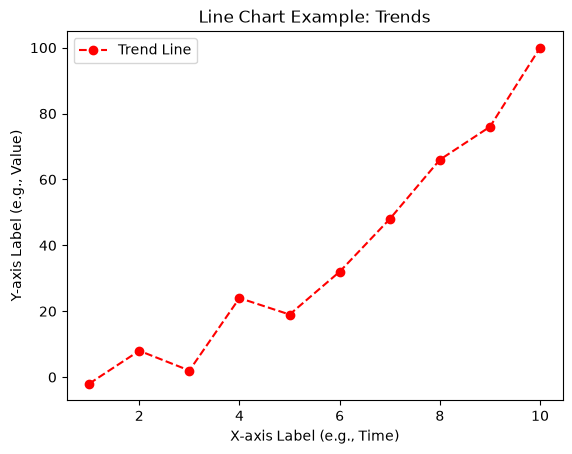

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. LINE CHART (Good for trends over time/continuous data)
x_data = np.arange(1, 11)
y_data = x_data ** 2 + np.random.randint(-10, 10, size=10)

plt.plot(x_data, y_data, color='red', linestyle='--', marker='o', label="Trend Line")

plt.title("Line Chart Example: Trends")
plt.xlabel("X-axis Label (e.g., Time)")
plt.ylabel("Y-axis Label (e.g., Value)")
plt.legend()
plt.show()

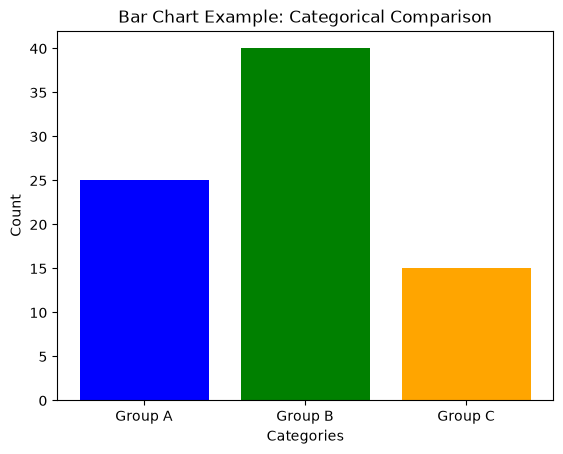

In [4]:
# 2. BAR CHART (Good for categorical/discrete data comparison)
categories = ['Group A', 'Group B', 'Group C']
values = [25, 40, 15]

plt.bar(categories, values, color=['blue', 'green', 'orange'])

plt.title("Bar Chart Example: Categorical Comparison")
plt.xlabel("Categories")
plt.ylabel("Count")
plt.show()

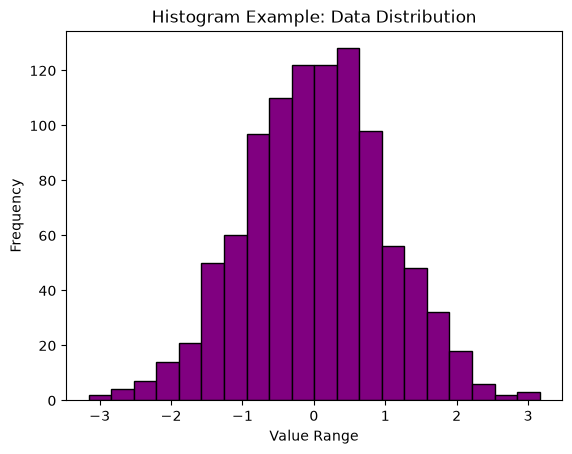

In [5]:
# 3. HISTOGRAM (Good for showing distribution of a single numerical variable)
# Generating normally distributed data
data_array = np.random.randn(1000)

plt.hist(data_array, bins=20, color='purple', edgecolor='black')

plt.title("Histogram Example: Data Distribution")
plt.xlabel("Value Range")
plt.ylabel("Frequency")
plt.show()

### C. Interpret patterns shown in charts
*   **Trends:** General direction of data over time (upward, downward, cyclical). Observed in line charts.
*   **Distribution shapes:** Observed in histograms. 
    *   *Normal (Gaussian):* Symmetrical, bell-shaped.
    *   *Skewed:* Asymmetrical, tail pulling to the left (negative) or right (positive).
    *   *Bimodal:* Having two distinct peaks.
*   **Outliers:** Data points differing significantly from other observations. In histograms, they appear as isolated bars far from the main data mass.

### D. Choose appropriate chart types for different kinds of data
*   **Line chart:** Continuous data, time-series, showing changes or trends.
*   **Bar chart:** Categorical or discrete data, comparing quantities across groups.
*   **Histogram:** Single-variable numerical data, frequency distribution.

### E. Use visualizations to support reasoning about data quality and ML readiness
*   **Identifying Outliers:** Extreme values in histograms that might skew ML model training (require capping or removal).
*   **Detecting Imbalance:** Bar charts of target variables showing class imbalance (e.g., 90% positive / 10% negative), indicating a need for resampling.
*   **Spotting Data Errors:** Unexpected gaps in line charts or massive spikes at zero in histograms (often missing data or erroneous default values).
*   **Assessing Distribution:** Checking if numerical features follow a normal distribution to decide if scaling is necessary for variance-sensitive algorithms.

## 3.6 - Explain the Importance of Data Quality in AI

Keywords: data quality, noise, outliers, inconsistent labels, preprocessing, bias, accuracy, dataset suitability 

### A. Identify common data problems
Raw data is rarely ready for Machine Learning. Common issues include:
*   **Noise:** Random errors or variance in a measured variable (e.g., sensor glitches, typos). It obscures the underlying pattern.
*   **Missing values:** Blank or null entries in the dataset. Models usually cannot process NaN values directly.
*   **Duplicates:** Identical rows appearing more than once, which can skew the model's perception of data frequency.
*   **Inconsistent formatting:** Same information recorded differently (e.g., dates as 'MM/DD/YYYY' vs 'DD-MM-YYYY', or categories like 'USA', 'U.S.A.', 'US').
*   **Labeling errors:** In supervised learning, when the target variable is marked incorrectly (e.g., an image of a dog labeled as a cat).

In [15]:
import pandas as pd
import numpy as np

# Mock dataset demonstrating common data problems
data = {
    'ID': [1, 2, 2, 4, 5], # Duplicate ID (2)
    'Country': ['USA', 'U.S.A.', 'Canada', 'USA', 'canada'], # Inconsistent formatting
    'Age': [25, 30, 30, np.nan, 22], # Duplicate row (index 1 & 2), Missing value (index 3)
    'Label_Is_Adult': [1, 1, 1, 1, 0] # Potential labeling issues depending on logic
}
df = pd.DataFrame(data)

# Identifying missing values
print("--- Missing Values ---")
print(df.isnull().sum())

# Identifying duplicates (by 'ID' key)
print("\n--- Duplicates ---")
print(df[df.duplicated(['ID'])])

# Checking unique values to spot inconsistent formatting
print("\n--- Inconsistent Formatting in 'Country' ---")
print(df['Country'].unique())

--- Missing Values ---
ID                0
Country           0
Age               1
Label_Is_Adult    0
dtype: int64

--- Duplicates ---
   ID Country   Age  Label_Is_Adult
2   2  Canada  30.0               1

--- Inconsistent Formatting in 'Country' ---
<StringArray>
['USA', 'U.S.A.', 'Canada', 'canada']
Length: 4, dtype: str


### B. Explain how poor data quality can lead to inaccurate or biased predictions
*   **The GIGO Principle (Garbage In, Garbage Out):** An AI model learns strictly from the data provided. If the input data is flawed, the model's output will be flawed.
*   **Inaccuracy:** Noise and outliers confuse the algorithm, forcing it to learn patterns that don't actually exist, leading to poor generalization on new data.
*   **Bias:** If the training dataset lacks representation of certain groups or contains human prejudices (historical bias), the model will learn and amplify these biases, leading to unfair or discriminatory predictions.

### C. Describe the role of preprocessing in AI workflows
Preprocessing is the essential intermediate step between raw data collection and model training. Its role is to:
1.  **Clean:** Handle missing values (imputation or removal) and drop duplicates.
2.  **Standardize:** Fix inconsistent formats and correct labeling errors.
3.  **Transform:** Convert text to numbers (encoding) and scale numerical values (normalization/standardization) so algorithms can process them efficiently.

### D. Recognize when a dataset is not suitable for training
A dataset should be rejected or heavily augmented if it is:
*   **Too small:** The algorithm won't have enough examples to find generalizable patterns, leading to severe overfitting (memorizing the data instead of learning).
*   **Low diversity:** The data only represents a narrow subset of real-world scenarios. The model will fail when encountering edge cases or data outside its narrow training scope.
*   **Incorrect or inconsistent labels:** If the "ground truth" provided to a supervised learning model contradicts itself, the algorithm cannot calculate a reliable gradient or decision boundary.

### E. Explain the link between clean data and model performance in simple terms
*   **Clear Signal:** Clean data provides a clear, strong "signal" for the algorithm to learn from, minimizing the "static" (noise).
*   **Data over Algorithm:** In applied machine learning, a simple algorithm trained on high-quality, clean data will almost always outperform a highly complex, state-of-the-art algorithm trained on messy, low-quality data.